# Generate artificial data

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

from scipy.stats import norm

# Set random seed for reproducibility
np.random.seed(42)

# Simulation settings
n = 1000                    # Number of observations
quantiles = [0.10, 0.50, 0.90]

# True data-generating parameters
beta_0 = 10
beta_1 = 2

# Heteroscedasticity parameter
gamma = 0.8

print("Simulation setup completed.")
print("Sample size:", n)
print("Quantiles:", quantiles)
print("True mean intercept:", beta_0)
print("True mean slope:", beta_1)
print("Heteroscedasticity parameter:", gamma)


Simulation setup completed.
Sample size: 1000
Quantiles: [0.1, 0.5, 0.9]
True mean intercept: 10
True mean slope: 2
Heteroscedasticity parameter: 0.8


In [4]:

# Generate explanatory variable (Education)
X = np.random.uniform(5, 20, n)

# Generate random errors from standard normal distribution
epsilon = np.random.normal(0, 1, n)

# Calculate error scale
error_scale = 1 + gamma * X

# Generate dependent variable (Income)
Y = beta_0 + beta_1 * X + error_scale * epsilon

# Create a DataFrame
data = pd.DataFrame({
    "Education": X,
    "Error": epsilon,
    "Error_Scale": error_scale,
    "Income": Y
})


data.head()


,Education,Error,Error_Scale,Income
0,10.618102,0.177701,9.494481,32.923382
1,19.260715,-1.335344,16.408572,26.610336
2,15.979909,0.380198,13.783927,47.200438
3,13.979877,0.610586,12.183902,45.399071
4,7.340280,0.559790,6.872224,28.527564


In [6]:
data.shape

(1000, 4)

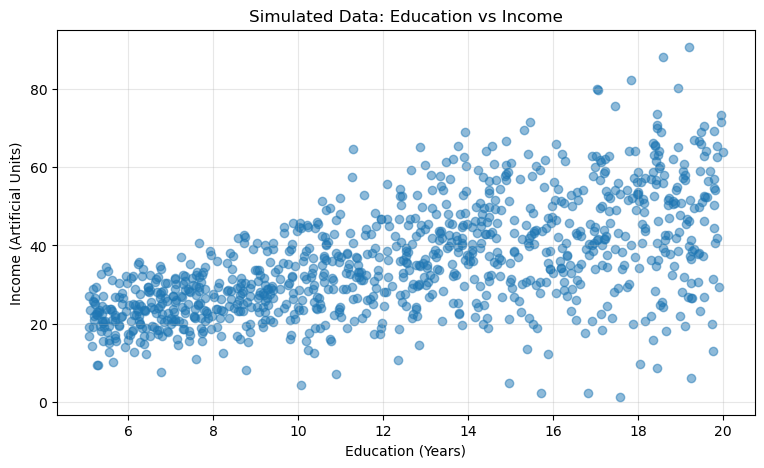

In [7]:

# Visualize the generated dataset

plt.figure(figsize=(9, 5))

plt.scatter(
    data["Education"],
    data["Income"],
    alpha=0.5
)

plt.xlabel("Education (Years)")
plt.ylabel("Income (Artificial Units)")
plt.title("Simulated Data: Education vs Income")

plt.grid(alpha=0.3)
plt.show()


# Estimates the regression models (OLS and Quantile Regression)

In [8]:
# OLS

X_design = sm.add_constant(data["Education"])
y = data["Income"]

ols_model = sm.OLS(y, X_design)
ols_result = ols_model.fit()

print(ols_result.summary())

                            OLS Regression Results                            
Dep. Variable:                 Income   R-squared:                       0.355
Model:                            OLS   Adj. R-squared:                  0.355
Method:                 Least Squares   F-statistic:                     550.0
Date:                Wed, 11 Nov 2026   Prob (F-statistic):           3.18e-97
Time:                        03:17:35   Log-Likelihood:                -3857.3
No. Observations:                1000   AIC:                             7719.
Df Residuals:                     998   BIC:                             7728.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         11.6430      1.085     10.731      0.0

In [9]:
## QR

qr_results = {}

for tau in quantiles:
    qr_model = sm.QuantReg(y, X_design)
    qr_result = qr_model.fit(q=tau)

    qr_results[tau] = qr_result

    print(f"\nQuantile: {tau}")
    print(qr_result.params)


Quantile: 0.1
const        11.823570
Education     0.786986
dtype: float64

Quantile: 0.5
const        10.365714
Education     2.042036
dtype: float64

Quantile: 0.9
const        14.317937
Education     2.872610
dtype: float64


# Comarison

In [10]:
comparison = pd.DataFrame({
    "Quantile": ["Mean (OLS)", "10th", "50th", "90th"],
    "True Slope": [
        beta_1,
        beta_1 + gamma * norm.ppf(0.10),
        beta_1 + gamma * norm.ppf(0.50),
        beta_1 + gamma * norm.ppf(0.90)
    ],
    "Estimated Slope": [
        ols_result.params["Education"],
        qr_results[0.10].params["Education"],
        qr_results[0.50].params["Education"],
        qr_results[0.90].params["Education"]
    ]
})

comparison

,Quantile,True Slope,Estimated Slope
0,Mean (OLS),2.000000,1.941305
1,10th,0.974759,0.786986
2,50th,2.000000,2.042036
3,90th,3.025241,2.872610


In [24]:
n_simulations = 500

print("Number of simulations:", n_simulations)

Number of simulations: 500


In [25]:
simulation_results = []

print("Result storage initialized.")

Result storage initialized.


In [ ]:
# Generate new datasets and estimate coefficients


for sim in range(n_simulations):

    # Generate a new dataset
    X_sim = np.random.uniform(5, 20, n)
    epsilon_sim = np.random.normal(0, 1, n)

    error_scale_sim = 1 + gamma * X_sim
    Y_sim = beta_0 + beta_1 * X_sim + error_scale_sim * epsilon_sim

    X_design_sim = sm.add_constant(X_sim)

    # Estimate OLS
    ols_sim = sm.OLS(Y_sim, X_design_sim).fit()

    result = {
        "OLS_Intercept": ols_sim.params[0],
        "OLS_Slope": ols_sim.params[1]
    }

    # Estimate Quantile Regression
    for tau in quantiles:
        qr_sim = sm.QuantReg(Y_sim, X_design_sim).fit(
            q=tau,
            max_iter=5000,
            p_tol=1e-4
        )

        result[f"QR_{tau}_Intercept"] = qr_sim.params[0]
        result[f"QR_{tau}_Slope"] = qr_sim.params[1]

    # Store results
    simulation_results.append(result)

print("Monte Carlo simulation completed.")
print("Total repetitions:", len(simulation_results))

Monte Carlo simulation completed.
Total repetitions: 500


In [27]:
results_df = pd.DataFrame(simulation_results)

print("Shape:", results_df.shape)
results_df.head()

Shape: (500, 8)


,OLS_Intercept,OLS_Slope,QR_0.1_Intercept,QR_0.1_Slope,QR_0.5_Intercept,QR_0.5_Slope,QR_0.9_Intercept,QR_0.9_Slope
0,8.247330,2.157439,7.171775,1.121374,9.509038,2.075434,8.764330,3.276082
1,12.046781,1.849389,11.495912,0.689188,11.095561,1.944291,15.702625,2.716826
2,10.112517,1.997319,10.848559,0.832047,10.758054,1.928238,9.954564,3.122621
3,9.247659,2.062583,6.971056,1.038003,9.461948,2.051804,12.624991,2.952241
4,10.041838,1.976409,8.458132,0.990081,11.970585,1.810535,12.174702,2.943517


In [28]:
print("Missing values in each column:")
print(results_df.isnull().sum())


Missing values in each column:
OLS_Intercept       0
OLS_Slope           0
QR_0.1_Intercept    0
QR_0.1_Slope        0
QR_0.5_Intercept    0
QR_0.5_Slope        0
QR_0.9_Intercept    0
QR_0.9_Slope        0
dtype: int64


In [29]:
simulation_results = []
convergence_log = []

print("Storage reset successfully.")

Storage reset successfully.


In [ ]:
# Repeat the simulation and record convergence

for sim in range(n_simulations):

    # Generate a new dataset
    X_sim = np.random.uniform(5, 20, n)
    epsilon_sim = np.random.normal(0, 1, n)

    error_scale_sim = 1 + gamma * X_sim
    Y_sim = beta_0 + beta_1 * X_sim + error_scale_sim * epsilon_sim

    X_design_sim = sm.add_constant(X_sim)

    # Estimate OLS
    ols_sim = sm.OLS(Y_sim, X_design_sim).fit()

    result = {
        "OLS_Intercept": ols_sim.params[0],
        "OLS_Slope": ols_sim.params[1]
    }

    # Estimate Quantile Regression
    for tau in quantiles:

        qr_sim = sm.QuantReg(Y_sim, X_design_sim).fit(
            q=tau,
            max_iter=5000,
            p_tol=1e-4
        )

        result[f"QR_{tau}_Intercept"] = qr_sim.params[0]
        result[f"QR_{tau}_Slope"] = qr_sim.params[1]

        # Record convergence information
        convergence_log.append({
            "Simulation": sim + 1,
            "Quantile": tau,
            "Iterations": qr_sim.iterations,
            "Converged": qr_sim.iterations < 5000
        })

    simulation_results.append(result)

print("Simulation completed.")
print("Total repetitions:", len(simulation_results))
print("Total QR fits:", len(convergence_log))

Simulation completed.
Total repetitions: 500
Total QR fits: 1500


In [31]:
# Check convergence status

convergence_df = pd.DataFrame(convergence_log)

print("Convergence summary:")
print(convergence_df["Converged"].value_counts())

print("\nConvergence by quantile:")
print(
    convergence_df.groupby("Quantile")["Converged"]
    .value_counts()
    .unstack(fill_value=0)
)

Convergence summary:
Converged
True    1500
Name: count, dtype: int64

Convergence by quantile:
Converged  True
Quantile       
0.1         500
0.5         500
0.9         500


In [32]:
# Recreate the final results DataFrame

results_df = pd.DataFrame(simulation_results)

print("Results shape:", results_df.shape)
results_df.head()

Results shape: (500, 8)


,OLS_Intercept,OLS_Slope,QR_0.1_Intercept,QR_0.1_Slope,QR_0.5_Intercept,QR_0.5_Slope,QR_0.9_Intercept,QR_0.9_Slope
0,9.040550,2.139336,7.243947,1.196358,8.766825,2.163315,10.909628,3.106618
1,10.188117,2.043879,8.057433,1.043566,10.788637,1.977196,10.204232,3.231294
2,8.591510,2.147000,9.124478,1.009646,9.786353,2.039751,9.416626,3.192993
3,10.711986,1.946973,8.776599,0.890117,9.557159,2.047126,13.846819,2.815760
4,11.150350,1.911899,7.807252,1.017184,11.170467,1.923236,11.280604,3.047556


In [33]:
# Calculate Bias, Variance and MSE

# True theoretical coefficient values
true_values = {
    "OLS_Intercept": beta_0,
    "OLS_Slope": beta_1,
    "QR_0.1_Intercept": beta_0 + norm.ppf(0.10),
    "QR_0.1_Slope": beta_1 + gamma * norm.ppf(0.10),
    "QR_0.5_Intercept": beta_0 + norm.ppf(0.50),
    "QR_0.5_Slope": beta_1 + gamma * norm.ppf(0.50),
    "QR_0.9_Intercept": beta_0 + norm.ppf(0.90),
    "QR_0.9_Slope": beta_1 + gamma * norm.ppf(0.90)
}

# Calculate performance measures
performance = []

for column, true_value in true_values.items():

    estimates = results_df[column]

    bias = estimates.mean() - true_value
    variance = estimates.var()
    mse = ((estimates - true_value) ** 2).mean()

    performance.append({
        "Parameter": column,
        "True Value": true_value,
        "Average Estimate": estimates.mean(),
        "Bias": bias,
        "Variance": variance,
        "MSE": mse
    })

performance_df = pd.DataFrame(performance)

performance_df.round(4)

,Parameter,True Value,Average Estimate,Bias,Variance,MSE
0,OLS_Intercept,10.0000,9.9693,-0.0307,0.9156,0.9147
1,OLS_Slope,2.0000,2.0025,0.0025,0.0078,0.0078
2,QR_0.1_Intercept,8.7184,8.6874,-0.0311,2.0159,2.0129
3,QR_0.1_Slope,0.9748,0.9797,0.0049,0.0188,0.0188
4,QR_0.5_Intercept,10.0000,10.0114,0.0114,1.0167,1.0148
5,QR_0.5_Slope,2.0000,1.9980,-0.0020,0.0092,0.0092
6,QR_0.9_Intercept,11.2816,11.2960,0.0144,1.9059,1.9023
7,QR_0.9_Slope,3.0252,3.0236,-0.0016,0.0183,0.0183


# Simulation Visualization

In [34]:
slope_estimates = results_df[
    [
        "OLS_Slope",
        "QR_0.1_Slope",
        "QR_0.5_Slope",
        "QR_0.9_Slope"
    ]
]

slope_estimates.head()

,OLS_Slope,QR_0.1_Slope,QR_0.5_Slope,QR_0.9_Slope
0,2.139336,1.196358,2.163315,3.106618
1,2.043879,1.043566,1.977196,3.231294
2,2.147000,1.009646,2.039751,3.192993
3,1.946973,0.890117,2.047126,2.815760
4,1.911899,1.017184,1.923236,3.047556


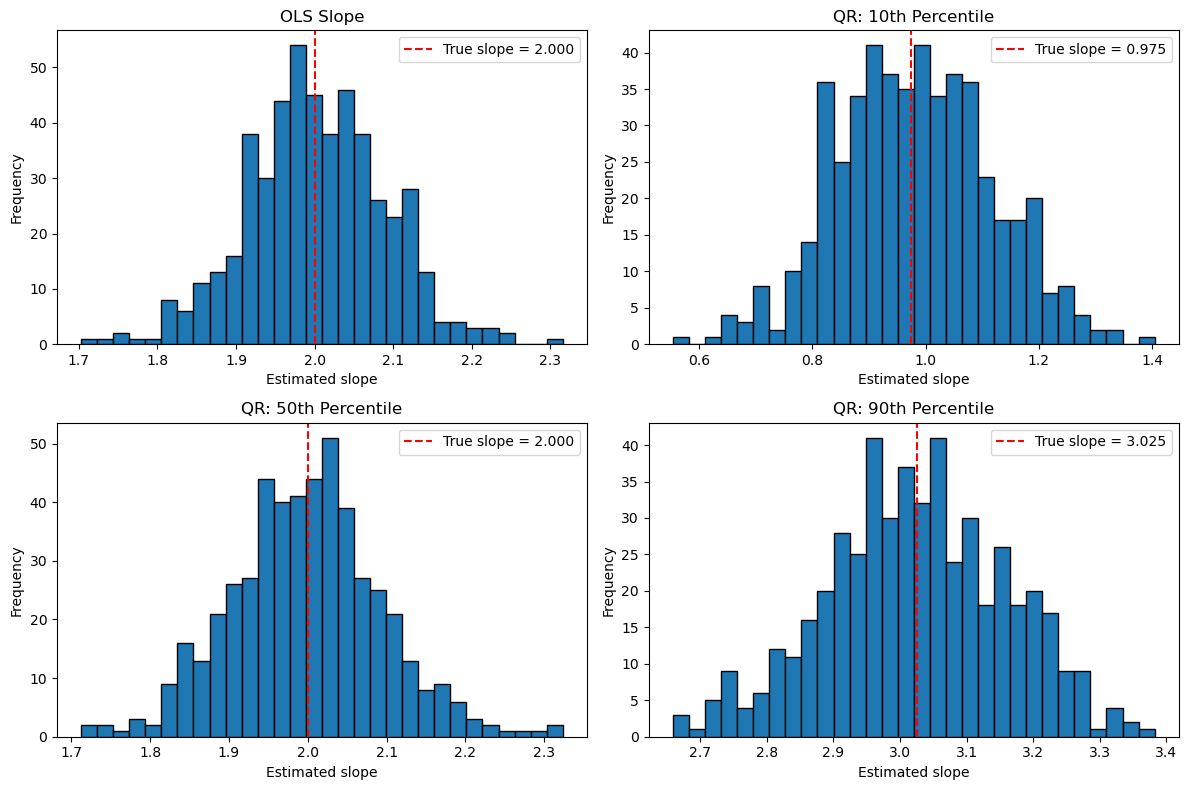

In [ ]:
# Visualize the distribution of slope estimates

true_slopes = [
    beta_1,
    beta_1 + gamma * norm.ppf(0.10),
    beta_1 + gamma * norm.ppf(0.50),
    beta_1 + gamma * norm.ppf(0.90)
]

titles = [
    "OLS Slope",
    "QR: 10th Percentile",
    "QR: 50th Percentile",
    "QR: 90th Percentile"
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for i, ax in enumerate(axes.flatten()):
    column = slope_estimates.columns[i]

    ax.hist(slope_estimates[column], bins=30, edgecolor="black")
    ax.axvline(
        true_slopes[i],
        color="red",
        linestyle="--",
        label=f"True slope = {true_slopes[i]:.3f}"
    )

    ax.set_title(titles[i])
    ax.set_xlabel("Estimated slope")
    ax.set_ylabel("Frequency")
    ax.legend()

plt.tight_layout()
plt.show()

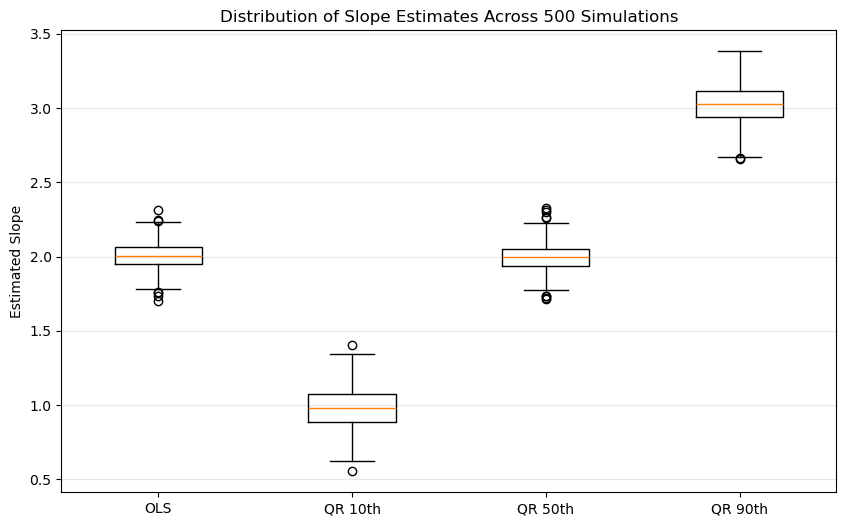

In [ ]:
# Compare the distributions using boxplots

plt.figure(figsize=(10, 6))

plt.boxplot(
    [
        slope_estimates["OLS_Slope"],
        slope_estimates["QR_0.1_Slope"],
        slope_estimates["QR_0.5_Slope"],
        slope_estimates["QR_0.9_Slope"]
    ],
    tick_labels=[
        "OLS",
        "QR 10th",
        "QR 50th",
        "QR 90th"
    ]
)

plt.ylabel("Estimated Slope")
plt.title("Distribution of Slope Estimates Across 500 Simulations")
plt.grid(axis="y", alpha=0.3)
plt.show()

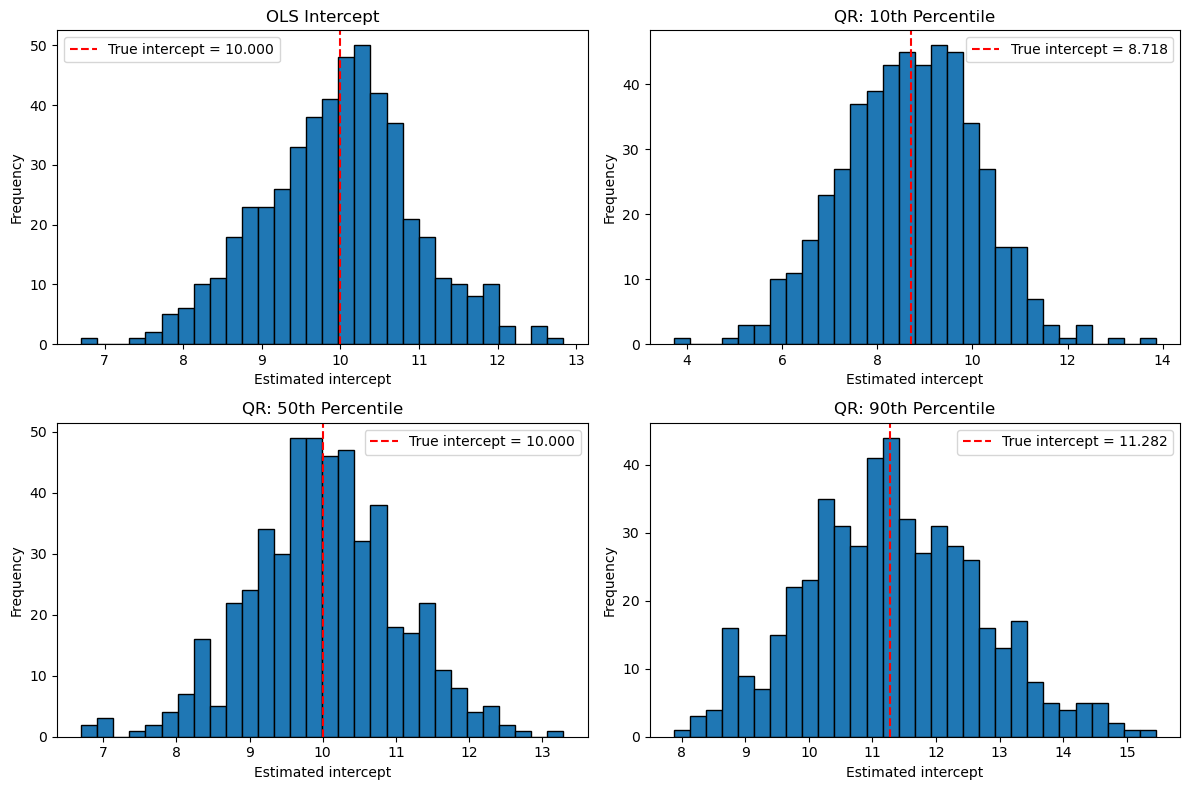

In [ ]:
# Visualize the intercept estimates

true_intercepts = [
    beta_0,
    beta_0 + norm.ppf(0.10),
    beta_0 + norm.ppf(0.50),
    beta_0 + norm.ppf(0.90)
]

titles = [
    "OLS Intercept",
    "QR: 10th Percentile",
    "QR: 50th Percentile",
    "QR: 90th Percentile"
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for i, ax in enumerate(axes.flatten()):
    column = [
        "OLS_Intercept",
        "QR_0.1_Intercept",
        "QR_0.5_Intercept",
        "QR_0.9_Intercept"
    ][i]

    ax.hist(results_df[column], bins=30, edgecolor="black")

    ax.axvline(
        true_intercepts[i],
        color="red",
        linestyle="--",
        label=f"True intercept = {true_intercepts[i]:.3f}"
    )

    ax.set_title(titles[i])
    ax.set_xlabel("Estimated intercept")
    ax.set_ylabel("Frequency")
    ax.legend()

plt.tight_layout()
plt.show()